<p><b>230266B - Jathunwaththa J.C.R.N.</b></p>

In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter

<h2><b>Question 01</b></h2>

In [ ]:
def scaled_log_kernel(sigma):
    radius = int(np.ceil(3 * sigma))
    coords = np.arange(-radius, radius + 1)

    x, y = np.meshgrid(coords, coords)
    r2 = x**2 + y**2

    kernel = (r2 - 2 * sigma**2) / (2 * np.pi * sigma**4) * np.exp(-r2 / (2 * sigma**2))
    kernel -= kernel.mean()
    
    return kernel.astype(np.float32)


def find_scale_space_maxima(scale_space, sigmas, threshold):
    neighborhood = np.ones((3, 3, 3), dtype=np.uint8)
    local_max = maximum_filter(scale_space, size=(3, 3, 3), mode="nearest")
    is_max = ((scale_space == local_max) & (scale_space > threshold))

    is_max[0, :, :] = False
    is_max[-1, :, :] = False

    ks, ys, xs = np.where(is_max)
    candidates = [(x, y, sigmas[k], scale_space[k, y, x]) for k, y, x in zip(ks, ys, xs)]

    return candidates

In [ ]:
im = cv.imread(
    './a2images/the_berry_farms_sunflower_field.jpeg',
    cv.IMREAD_REDUCED_COLOR_4
)

gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY)

sigmas = np.arange(0.5, 10, 0.5)
gray_float = gray.astype(np.float32) / 255.0
responses = []

for sigma in sigmas:
    kernel = scaled_log_kernel(sigma)
    response = cv.filter2D(
        gray_float,
        cv.CV_32F,
        kernel,
        borderType=cv.BORDER_REFLECT
    )
    responses.append(np.abs(response))

scale_space = np.stack(responses, axis=0)
candidates = find_scale_space_maxima(scale_space, sigmas, threshold=0.29)
print("Number of candidate blobs:", len(candidates))

In [ ]:
result = cv.cvtColor(gray, cv.COLOR_GRAY2BGR)

# Sort by estimated radius, largest first
candidates.sort(key=lambda c: c[2], reverse=True)

for x, y, sigma, response in candidates:
    radius = int(round(np.sqrt(2) * sigma))
    cv.circle(result, (x, y), radius, (0, 255, 0), 2)

plt.figure(figsize=(12, 8))
plt.imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
plt.title("Largest LoG Blob Candidates")
plt.axis("off")
plt.show()

# Parameters of the largest circle
if candidates:
    x, y, sigma, response = candidates[1]
    radius = int(round(np.sqrt(2) * sigma))
    print(f"Largest circle: center=({x}, {y}), radius={radius}, response={response}")


<h2><b>Question 02</b></h2>

<h4>Data generation</h4>

In [ ]:
# Generation of a Noisy Point Set Conforming to a Line and a Circle
import numpy as np
from scipy.optimize import minimize
from scipy import linalg
import matplotlib.pyplot as plt

# np.random.seed(0)
N = 100
half_n = N//2
r = 10
x0_gt, y0_gt = 2, 3  # Center
s = r/16
t = np.random.uniform(0, 2*np.pi, half_n)
n = s*np.random.randn(half_n)
x, y = x0_gt + (r + n)*np.cos(t), y0_gt + (r + n)*np.sin(t)
X_circ = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))
s = 1.
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m*x + b + s*np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))
X = np.vstack((X_circ, X_line))  # All points

fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.scatter(X_line[:, 0], X_line[:, 1], label='Line')
ax.scatter(X_circ[:, 0], X_circ[:, 1], label='Circle')
circle_gt = plt.Circle((x0_gt, y0_gt), r, color='g', fill=False, label='Ground truth circle')
ax.add_patch(circle_gt)
ax.plot((x0_gt), (y0_gt), '+', color='g')
x_min, x_max = ax.get_xlim()
x_ = np.array([x_min, x_max])
y_ = m*x_ + b
plt.plot(x_, y_, color='m', label='Ground truth line')
plt.legend()

<h4>Fitting the line</h4>

In [ ]:
num_iterations = 1000
threshold = 1.5
min_inliers = 30
line_inlier_mask = None

best = {'count': 0, 'err': np.inf}

for _ in range(num_iterations):
    i, j = np.random.choice(len(X), size=2, replace=False)
    p1, p2 = X[i], X[j]
    dx, dy = p2 - p1
    norm = np.hypot(dx, dy)
    if norm < 1e-9:
        continue

    nx, ny = -dy / norm, dx / norm
    d = nx * p1[0] + ny * p1[1]

    dist = np.abs(X @ np.array([nx, ny]) - d)
    mask = dist < threshold
    if mask.sum() < min_inliers:
        continue

    # Total least squares refit on the consensus set
    pts = X[mask]
    centroid = pts.mean(axis=0)
    _, _, Vt = np.linalg.svd(pts - centroid)
    nx, ny = Vt[1]
    d = nx * centroid[0] + ny * centroid[1]

    # Re-evaluate the refitted line on all points
    dist = np.abs(X @ np.array([nx, ny]) - d)
    mask = dist < threshold
    count = mask.sum()
    err = np.mean(dist[mask] ** 2)

    if count > best['count'] or (count == best['count'] and err < best['err']):
        best = dict(count=count, err=err, a=nx, b=ny, d=d, mask=mask)
        line_inlier_mask = mask

a_best, b_best, d_best = best['a'], best['b'], best['d']

<h4>Fitting the circle</h4>

In [ ]:
# Remove the inliers of the best fitting line from the dataset
X_remaining = X[~line_inlier_mask]

num_iterations = 1000
threshold = 1.5
min_inliers = 30

best = {'count': 0, 'err': np.inf}

for _ in range(num_iterations):
    i, j, k = np.random.choice(len(X_remaining), size=3, replace=False)
    p1, p2, p3 = X_remaining[i], X_remaining[j], X_remaining[k]
    # Fit a circle to the three points
    A = np.array([
        [2*(p2[0]-p1[0]), 2*(p2[1]-p1[1])],
        [2*(p3[0]-p1[0]), 2*(p3[1]-p1[1])]
    ])
    b_vec = np.array([
        p2[0]**2 + p2[1]**2 - p1[0]**2 - p1[1]**2,
        p3[0]**2 + p3[1]**2 - p1[0]**2 - p1[1]**2
    ])
    try:
        x0, y0 = np.linalg.solve(A, b_vec)
    except np.linalg.LinAlgError:
        continue
    r = np.hypot(p1[0]-x0, p1[1]-y0)

    dist = np.abs(np.hypot(X_remaining[:,0]-x0, X_remaining[:,1]-y0) - r)
    mask = dist < threshold
    if mask.sum() < min_inliers:
        continue

    count = mask.sum()
    err = np.mean(dist[mask] ** 2)

    if count > best['count'] or (count == best['count'] and err < best['err']):
        best = dict(count=count, err=err, x0=x0, y0=y0, r=r, mask=mask)

x0_best, y0_best, r_best = best['x0'], best['y0'], best['r']


# Plot ground truth and best fitting shapes
fig, ax = plt.subplots(1, 1, figsize=(8, 8))

ax.scatter(X_line[:, 0], X_line[:, 1], label='Line')
ax.scatter(X_circ[:, 0], X_circ[:, 1], label='Circle')

x_min, x_max = ax.get_xlim()
x_ = np.array([x_min, x_max])

y_ = m*x_ + b
y_pred = (d_best - a_best * x_) / b_best
circle_gt = plt.Circle((x0_gt, y0_gt), r, color='g', fill=False, label='Ground truth circle')
circle_pred = plt.Circle((x0_best, y0_best), r_best, color='r', fill=False, label='Best fitting circle')

ax.plot((x0_gt), (y0_gt), '+', color='g')
ax.plot((x0_best), (y0_best), '+', color='r')
ax.add_patch(circle_pred)
ax.add_patch(circle_gt)
plt.plot(x_, y_, color='m', label='Ground truth line')
plt.plot(x_, y_pred, color='red', label='Best fitting line')

plt.legend()
plt.show()

If the circle is fitted first, RANSAC may select three points from the line, producing a circle with a very large radius. Since a small arc of a large circle closely resembles a straight line, many line points may fall within the circle's inlier threshold. Consequently, the circle model may incorrectly classify line points as inliers.

<h2><b>Question 03</b></h2>

In [16]:
def compute_homography(src_pts, dst_pts):
    A, b = [], []
    for (x, y), (u, v) in zip(src_pts, dst_pts):
        A.append([x, y, 1, 0, 0, 0, -u * x, -u * y])
        b.append(u)
        A.append([0, 0, 0, x, y, 1, -v * x, -v * y])
        b.append(v)
    h = np.linalg.solve(np.asarray(A, dtype=np.float64), np.asarray(b, dtype=np.float64))
    return np.append(h, 1).reshape(3, 3)


def apply_homography(background_bgr, overlay_bgr, picker_src, picker_dst):
    src_pts = picker_src.get()
    dst_pts = picker_dst.get()

    H = compute_homography(src_pts, dst_pts)
    h, w = background_bgr.shape[:2]
    warped_bgr = cv.warpPerspective(overlay_bgr, H, (w, h))

    mask = np.full(overlay_bgr.shape[:2], 255, dtype=np.uint8)
    warped_mask = cv.warpPerspective(mask, H, (w, h))
    warped_bgr = cv.warpPerspective(overlay_bgr, H, (w, h))
    result_bgr = background_bgr.copy()
    result_bgr[warped_mask > 0] = warped_bgr[warped_mask > 0]

    fig, ax = plt.subplots(1, 2, figsize=(8, 5))
    ax[0].imshow(background_rgb)
    ax[0].set_title("Background Image")
    ax[0].axis("off")

    ax[1].imshow(overlay_rgb)
    ax[1].set_title("Overlay Image")
    ax[1].axis("off")
    plt.show()

    fig, ax = plt.subplots(1, 1, figsize=(8, 5))
    result_rgb = cv.cvtColor(result_bgr, cv.COLOR_BGR2RGB)
    ax.imshow(result_rgb)
    ax.set_title("Homography Overlay")
    ax.axis("off")
    plt.show()


class PointPicker:
    def __init__(self, image_rgb, title, n_points=4):
        self.n = n_points
        self.title = title
        self.pts = []
        self.fig, self.ax = plt.subplots(figsize=(10, 6))
        self.ax.imshow(image_rgb)
        self.ax.set_title(f"{title} - click {n_points} points in order")
        self.ax.axis("off")
        self.marks = self.ax.plot([], [], "r+", markersize=14, mew=2)[0]
        self.cid = self.fig.canvas.mpl_connect("button_press_event", self.on_click)
        plt.show()

    def on_click(self, event):
        # Ignore clicks outside the image, and while zoom/pan is active
        if event.inaxes != self.ax or len(self.pts) >= self.n:
            return
        tb = getattr(self.fig.canvas, "toolbar", None)
        if tb is not None and tb.mode != "":
            return
        self.pts.append((event.xdata, event.ydata))
        self.ax.text(event.xdata + 5, event.ydata - 5, str(len(self.pts)),
                     color="yellow", fontsize=14, weight="bold")
        xs, ys = zip(*self.pts)
        self.marks.set_data(xs, ys)
        if len(self.pts) == self.n:
            self.fig.canvas.mpl_disconnect(self.cid)
            self.ax.set_title(f"{self.title}")
        self.fig.canvas.draw_idle()

    def get(self):
        if len(self.pts) != self.n:
            raise ValueError(f"Only {len(self.pts)}/{self.n} points selected.")
        return np.asarray(self.pts, dtype=np.float32)

<h5><b>First pair of images</b></h5>

In [ ]:
%matplotlib widget

background_bgr = cv.imread("./a2images/billboard_road.jpg")
overlay_bgr = cv.imread("./a2images/veil_nebula.jpg")
background_rgb = cv.cvtColor(background_bgr, cv.COLOR_BGR2RGB)
overlay_rgb = cv.cvtColor(overlay_bgr, cv.COLOR_BGR2RGB)

picker_src = PointPicker(overlay_rgb, "Overlay image")
picker_dst = PointPicker(background_rgb, "Background image")

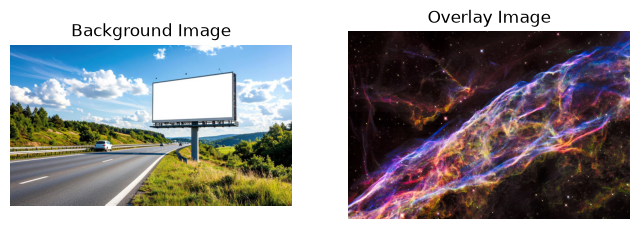

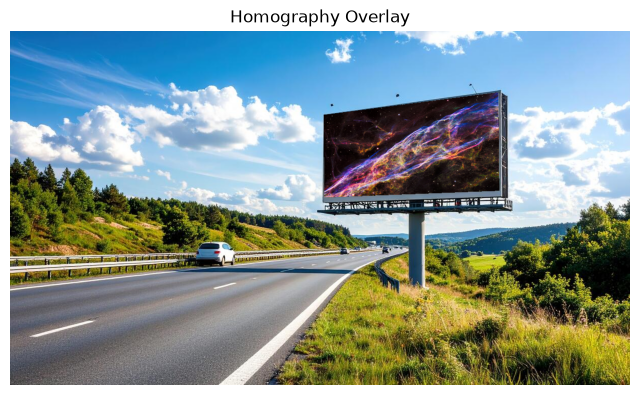

In [17]:
%matplotlib inline
plt.close('all')
apply_homography(background_bgr, overlay_bgr, picker_src, picker_dst)

What's more beautiful than a fragment of a long-dead star lighting up a roadside billboard? The Veil Nebula, a remnant of a supernova that once tore a star apart, brings a glimpse of the distant cosmos into an ordinary scene on Earth. Its vivid blues, reds, and delicate filaments make it a striking choice for the billboard.

<h5><b>Second pair of images</b></h5>

In [ ]:
%matplotlib widget

background_bgr = cv.imread("./a2images/forest_cabin.jpg")
overlay_bgr = cv.imread("./a2images/messier101.jpg")
background_rgb = cv.cvtColor(background_bgr, cv.COLOR_BGR2RGB)
overlay_rgb = cv.cvtColor(overlay_bgr, cv.COLOR_BGR2RGB)

picker_src = PointPicker(overlay_rgb, "Overlay image")
picker_dst = PointPicker(background_rgb, "Background image")

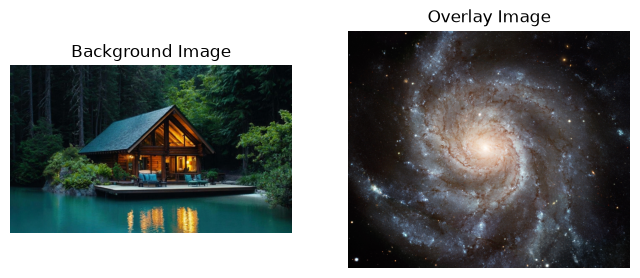

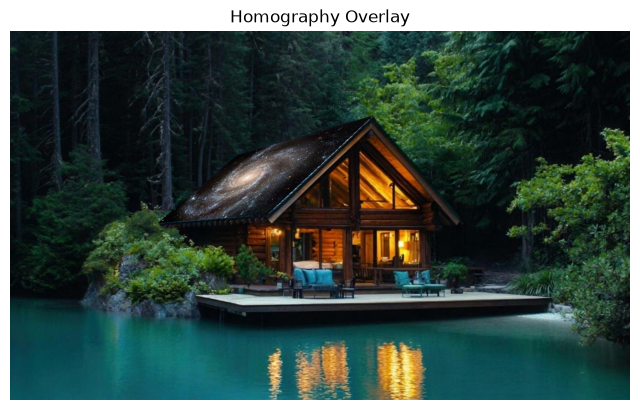

In [27]:
%matplotlib inline
plt.close('all')
apply_homography(background_bgr, overlay_bgr, picker_src, picker_dst)

Deep within a quiet forest, a glimpse of a distant galaxy appears across the wooden ceiling of a secluded cabin. Messier 101, with its delicate spiral arms and luminous blue and white hues, brings the vast beauty of the cosmos into the warmth of a natural retreat, blending the wonder of the universe with the serenity of the forest.